# Aula 01 - O Baseline e a Alta Dimensionalidade em um Benchmark Sintético

**Disciplina:** Inteligência Artificial Explicável (XAI) & Otimização de Modelos  
**Autor / Pesquisador:** Eduardo Lázaro Roesler de Oliveira  
**Instituição:** UNESP — Universidade Estadual Paulista "Júlio de Mesquita Filho" (Mestrado)  

> **Escopo:** Todos os dados desta aula são sintéticos. Os exemplos de saúde são apenas ilustrativos; não representam pacientes, exames, biomarcadores reais ou resultados clínicos.

> 🔙 **De onde viemos:** No aprendizado de máquina tradicional, costuma-se acreditar no mantra ingênuo de que *"quanto mais dados e colunas tivermos, melhor o modelo irá aprender"*. No entanto, na prática de ciência de dados (especialmente na saúde e bioinformática), coletar dezenas de exames e variáveis sem critério introduz ruído estatístico, correlações espúrias e o temido **Mal da Dimensionalidade** (*The Curse of Dimensionality*).
> 🎯 **Objetivo Principal da Aula:** Construir um benchmark sintético controlado com 40 atributos (10 informativos, 10 redundantes e 20 de ruído), treinar um classificador de referência (**Baseline**) com **Random Forest**, mensurar seu custo computacional de treinamento e inferência e calcular métricas preditivas (**Acurácia, F1-Score, ROC-AUC, Matriz de Confusão e Curva ROC**).
> 🚀 **Para onde vamos:** Na Aula 02, usaremos a **Inteligência Artificial Explicável (XAI)** e a Teoria dos Jogos Cooperativos de Lloyd Shapley (**SHAP**) para examinar como o modelo usa as variáveis sintéticas; isso não identifica biomarcadores reais nem causas.

## Organização Tática da Aula

| Módulo | Atividade | Foco Pedagógico |
| :--- | :--- | :--- |
| **Módulo 1** | **Fundamentação Teórica & O Desafio da Dimensionalidade** | O problema da explosão do espaço vetorial e por que atributos inúteis degradam o tempo e a precisão do modelo. |
| **Módulo 2** | **O Mecanismo por Dentro & Anatomia dos Dados Sintéticos** | A distinção entre atributos informativos, redundantes e ruído puro, e o uso descritivo de métricas preditivas. |
| **Módulo 3** | **Prática Guiada no Google Colab** | 7 blocos de código em Python minuciosamente comentados linha por linha, com caixas de dúvidas e gráficos interativos. |
| **Módulo 4** | **Prática Orientada & Experimentação Fácil** | Experimentação com aumento de ruído nos rótulos (*flip_y*) e injeção de novos ruídos. |
| **Módulo 5** | **Checklist de Autonomia & Bibliografia** | Autoavaliação do estudante e referências seminais de Machine Learning. |

## Módulo 1: Fundamentação Teórica & O Desafio da Dimensionalidade

### 1.1 O que é o "Mal da Dimensionalidade"?
Em um benchmark de classificação binária, cada atributo atua como uma **dimensão geométrica adicional** no espaço vetorial. O rótulo de saúde usado nos exemplos é apenas ilustrativo e não corresponde a diagnóstico real.

1. **Espaço Esparso:** À medida que o número de variáveis ($d$) cresce linearmente, o volume do espaço cresce **exponencialmente** ($2^d$). Os pontos de dados tornam-se incrivelmente distantes uns dos outros, tornando quase impossível encontrar padrões robustos sem uma quantidade colossal de amostras.
2. **Armadilha do Ruído:** Se um algoritmo recebe 20 colunas de ruído aleatório, por pura coincidência estatística o modelo encontrará correlações ilusórias com a patologia durante o treino, levando ao temido **Superajuste (Overfitting)**.
3. **Custo Operacional e Latência:** Cada atributo a mais exige memória RAM, tempo de CPU para dividir árvores de decisão e, no hospital real, representa **custo financeiro e tempo de espera** para o paciente colher exames desnecessários.

```mermaid
graph TD
    A["🏥 40 Variáveis Coletadas do Paciente"] --> B["🧪 10 Biomarcadores Reais<br/>(Informação Genuína)"]
    A --> C["📋 10 Exames Redundantes<br/>(Colineares aos biomarcadores)"]
    A --> D["🌪️ 20 Ruídos Metabólicos<br/>(Aleatoriedade sem valor diagnóstico)"]
    B --> E["🤖 MODELO BASELINE (RANDOM FOREST)<br/>Precisa aprender a separar sinal do ruído!"]
    C --> E
    D --> E
    E --> F["⏱️ Alto Custo Computacional & Risco de Overfitting"]
```

> ⚔️ **Analogia Geek — O Inventário Pesado de um RPG:**
> Imagine que seu personagem em um jogo de RPG tem uma capacidade de carga de 40 itens no inventário. Desses 40 itens, 10 são poções de cura e espadas mágicas (**informativos**), 10 são armaduras repetidas que ocupam espaço sem dar bônus extra (**redundantes**), e 20 são pedras e galhos velhos apanhados no chão (**ruído**). O excesso de tralhas torna seu guerreiro lento na esquiva (**alta latência**) e faz você perder tempo procurando a poção certa na hora da batalha. Nosso objetivo em XAI será limpar essa mochila!

> 💡 **Curiosidade da Aula — O Fenômeno de Hughes (Hughes Phenomenon):**
> Em **1968, Gordon F. Hughes** publicou um estudo seminal provando matematicamente que, mantendo-se constante o número de amostras de treino, a precisão preditiva de um classificador primeiro cresce conforme adicionamos variáveis, atinge um pico ótimo e depois **cai vertiginosamente** à medida que continuamos adicionando atributos! Esse pico é exatamente o que buscaremos reencontrar através da redução guiada por explicabilidade.

> 💡 **Em 1 Frase:** O modelo Baseline serve como a nossa régua de comparação: ele representa o desempenho e o custo computacional de quem tenta resolver o problema usando "força bruta" com todas as variáveis disponíveis.

## Módulo 2: O Mecanismo por Dentro & Regras Práticas

### 2.1 Tipologia dos Atributos em Problemas Reais

| Tipo de Atributo | Definição Matemática/Prática | Exemplo Clínico | Efeito no Algoritmo |
| :--- | :--- | :--- | :--- |
| **Informativo** | Foi gerado com sinal preditivo relacionado ao alvo $y$ no dataset sintético; isso não implica causalidade. | Atributo informativo simulado, sem equivalência a exame ou biomarcador real. | Pode influenciar os cortes do modelo e as métricas preditivas. |
| **Redundante** | Combinação linear ou fortemente correlacionada com um atributo informativo. | Hemoglobina Glicada vs. Glicemia Média Estimada; Peso e IMC. | Dilui a importância das variáveis; consome tempo de treino sem trazer nova informação. |
| **Ruído Puro** | Distribuição gaussiana aleatória independente de $y$ ($P(y \mid X_{ruído}) = P(y)$). | Horóscopo do paciente; número do calçado; ruído térmico do sensor. | Gera ramificações espúrias na árvore; facilita overfitting e atrasa a inferência. |

### 2.2 As Métricas de Desempenho Clínico Essenciais

1. **Acurácia:** Proporção global de acertos sobre o total de casos.
   $$\text{Acurácia} = \frac{VP + VN}{VP + VN + FP + FN}$$
   *Cuidado:* Em dados desbalanceados (ex: 95% saudáveis e 5% doentes), um modelo "burro" que chuta sempre saudável terá 95% de acurácia, mas matará todos os pacientes!
2. **F1-Score (Média Harmônica entre Precisão e Recall):** métrica descritiva de desempenho usada neste benchmark, sem interpretação clínica.
   $$F_1 = 2 \cdot \frac{\text{Precisão} \cdot \text{Recall}}{\text{Precisão} + \text{Recall}} = \frac{2 \cdot VP}{2 \cdot VP + FP + FN}$$
3. **ROC-AUC (Área sob a Curva ROC):** Probabilidade de o classificador pontuar um caso positivo aleatório acima de um caso negativo aleatório. $0.50$ equivale ao chute de uma moeda e $1.0$ representa a separação perfeita.

> 💡 **Em 1 Frase:** Acurácia, F1 e ROC-AUC resumem aspectos distintos do desempenho preditivo; nenhuma métrica, isoladamente, garante adequação clínica ou segurança.

## Módulo 3: Prática Guiada no Google Colab

Abra o [Google Colab](https://colab.research.google.com), crie um novo Notebook e acompanhe os blocos de código abaixo.

> **Roteiro de estudo:** Execute uma célula por vez. Preste atenção em como os 40 atributos são criados com papéis bem definidos e como o Random Forest é cronometrado com precisão de microssegundos usando `time.perf_counter()`.

### Bloco 1.1 — Instalação dos Pacotes e Preparação do Ambiente

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que precisamos rodar `!pip install` no Google Colab se o Python já vem instalado?**  
> O Google Colab oferece máquinas virtuais limpas na nuvem com pacotes básicos, mas bibliotecas avançadas de explicabilidade (SHAP, LIME) e otimização (Optuna) precisam ser instaladas na sessão para que os módulos futuros funcionem perfeitamente.

In [1]:
# 1. Executamos o comando de terminal do Colab para instalar as bibliotecas de XAI e Otimizacao
!pip install shap lime optuna statsmodels -q

# 2. Exibimos a confirmacao de que a instalacao foi concluida com sucesso
print("[OK] Ambiente Google Colab configurado com sucesso para as aulas de XAI!")

[OK] Ambiente Google Colab configurado com sucesso para as aulas de XAI!



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


---

### Bloco 1.2 — Importação das Bibliotecas Fundamentais

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que usamos `time.perf_counter()` em vez de `time.time()`?**  
> O `time.perf_counter()` acessa o clock de mais alta resolução disponível no processador do computador, ideal para medir execuções rápidas de algoritmos com precisão de frações de milissegundos.

In [2]:
# 1. Importamos a biblioteca de medicao de tempo de alta precisao
import time

# 2. Importamos as bibliotecas padrao de computacao numerica e manipulacao tabular
import numpy as np
import pandas as pd

# 3. Importamos as bibliotecas graficas para geracao de figuras estatisticas
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Importamos o gerador de datasets sinteticos com controle estrito de informatividade
from sklearn.datasets import make_classification

# 5. Importamos a funcao para divisao estratificada entre treino e teste
from sklearn.model_selection import train_test_split

# 6. Importamos o classificador Random Forest (Ensemble de Arvores de Decisao)
from sklearn.ensemble import RandomForestClassifier

# 7. Importamos o conjunto completo de metricas de avaliacao de classificadores
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

# 8. Configuramos o estilo estetico dos graficos para um padrao visual limpo e moderno
sns.set_theme(style="whitegrid", palette="deep")

# 9. Exibimos mensagem confirmando o carregamento dos modulos
print("[OK] Todas as dependencias de Machine Learning foram importadas com sucesso!")

[OK] Todas as dependencias de Machine Learning foram importadas com sucesso!


---

### Bloco 1.3 — Gerando o Dataset Sintético Clínico (40 Atributos)

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que faz o parâmetro `flip_y=0.03` na função `make_classification`?**  
> Ele introduz 3% de ruído proposital nos rótulos de diagnóstico. Na vida real, biópsias podem sofrer falso-positivos laboratoriais ou diagnósticos errôneos de 2% a 5%. Esse ruído impede que o modelo atinja 100% de acurácia irrealista.

In [3]:
# 1. Definimos a funcao responsavel por sintetizar o conjunto de dados clinicos
def gerar_dataset_sintetico_saude(n_samples=2000, n_features=40, n_informative=10, n_redundant=10, random_state=42):
    """
    Gera um dataset sintético didático:
    - 2.000 observações (linhas)
    - 40 atributos totais (colunas)
    - 10 atributos informativos sintéticos
    - 10 atributos redundantes (correlacionados)
    - 20 atributos de ruído (sem sinal preditivo construído)
    """
    # 2. Geramos as matrizes brutas controlando informatividade e redundancia
    X_raw, y = make_classification(
        n_samples=n_samples,         # Total de observacoes sinteticas
        n_features=n_features,       # Total de atributos por observacao
        n_informative=n_informative, # Atributos informativos para a classe sintetica
        shuffle=False, # Mantem os grupos de atributos na ordem esperada
        n_redundant=n_redundant,     # Quantidade de exames redundantes/repetidos
        n_repeated=0,                # Nao permitimos colunas duplicadas identicas
        n_classes=2,                 # Classificacao binaria com classes sinteticas 0 e 1
        weights=[0.6, 0.4],          # Proporcoes definidas para as classes sinteticas
        flip_y=0.03,                 # 3% de ruido artificial nos rotulos
        random_state=random_state    # Semente pseudoaleatoria para garantir reprodutibilidade
    )
    
    # 3. Construímos uma lista de nomes semânticos e didáticos para as colunas
    feature_names = (
        [f"biomarcador_{i+1}" for i in range(n_informative)] +
        [f"exame_redundante_{i+1}" for i in range(n_redundant)] +
        [f"ruido_metabolico_{i+1}" for i in range(n_features - n_informative - n_redundant)]
    )
    
    # 4. Encapsulamos a matriz numerica em um DataFrame do Pandas com os cabecalhos nomeados
    df_X = pd.DataFrame(X_raw, columns=feature_names)
    
    # 5. Retornamos o DataFrame de caracteristicas X e o vetor de diagnosticos y
    return df_X, y

# 6. Invocamos a funcao para instanciar nossos dados clinicos
df_X, y = gerar_dataset_sintetico_saude()

# 7. Exibimos a confirmacao das dimensoes da tabela gerada
print(f"[*] Dataset sintetico gerado: {df_X.shape[0]} observacoes por {df_X.shape[1]} atributos!")
print(f"[*] Distribuicao de classes: {np.bincount(y)[0]} Saudaveis (0) e {np.bincount(y)[1]} com Patologia (1)")

[*] Dataset sintetico gerado: 2000 observacoes por 40 atributos!
[*] Distribuicao de classes: 1197 Saudaveis (0) e 803 com Patologia (1)


---

### Bloco 1.4 — Divisão Estratificada em Conjuntos de Treino e Teste

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que é crucial usar `stratify=y` na divisão de treino e teste?**  
> A estratificação garante que a proporção exata entre pessoas saudáveis (60%) e doentes (40%) seja mantida identicamente tanto no conjunto de treino quanto no de teste, evitando que o teste fique com viés de classe.

In [4]:
# 1. Realizamos a divisao estratificada separando 75% para treinamento e 25% para teste cego
X_train, X_test, y_train, y_test = train_test_split(
    df_X,                    # Matriz completa de atributos
    y,                       # Vetor de rotulos reais
    test_size=0.25,          # 25% dos dados reservados exclusivamente para teste
    random_state=42,         # Semente fixa para que os mesmos pacientes vao para teste
    stratify=y               # Mantem a mesma proporcao de doentes nos dois conjuntos
)

# 2. Exibimos o formato resultante dos conjuntos particionados
print(f"[*] Conjunto de Treinamento: {X_train.shape[0]} pacientes (75%)")
print(f"[*] Conjunto de Teste Cego:  {X_test.shape[0]} pacientes (25%)")

[*] Conjunto de Treinamento: 1500 pacientes (75%)
[*] Conjunto de Teste Cego:  500 pacientes (25%)


---

### Bloco 1.5 — Treinamento do Modelo Baseline e Extração de Métricas

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que significa o parâmetro `n_jobs=1`?**  
> Ele instrui o algoritmo a rodar em uma única thread da CPU. Fixar `n_jobs=1` é fundamental para medições de tempo científicas e justas, eliminando variações de concorrência de múltiplos núcleos.

In [5]:
# 1. Definimos a funcao que treina o baseline e extrai o perfil de desempenho e tempo
def treinar_e_avaliar_baseline(X_train, X_test, y_train, y_test, random_state=42):
    """
    Treina o modelo Baseline (Random Forest) com todas as 40 variáveis e mede latências.
    """
    # 2. Instanciamos a floresta aleatoria com 100 arvores de decisao independentes
    modelo = RandomForestClassifier(n_estimators=100, random_state=random_state, n_jobs=1)
    
    # 3. Marcamos o instante inicial antes do ajuste do modelo
    inicio_treino = time.perf_counter()
    
    # 4. Treinamos a floresta aleatoria no conjunto de dados completo (40 atributos)
    modelo.fit(X_train, y_train)
    
    # 5. Calculamos o tempo total decorrido na etapa de treino em segundos
    tempo_treino = time.perf_counter() - inicio_treino
    
    # 6. Marcamos o instante inicial antes de realizar a predicao do teste
    inicio_inf = time.perf_counter()
    
    # 7. Obtemos os diagnosticos binarios preditos (0 ou 1)
    y_pred = modelo.predict(X_test)
    
    # 8. Obtemos a probabilidade continua de pertencer a classe patologica (coluna de indice 1)
    y_proba = modelo.predict_proba(X_test)[:, 1]
    
    # 9. Calculamos o tempo gasto para processar toda a fila de pacientes do teste
    tempo_inferencia = time.perf_counter() - inicio_inf
    
    # 10. Consolidamos todas as metricas diagnosticas em um dicionario organizado
    metricas = {
        "acuracia": accuracy_score(y_test, y_pred),
        "f1_score": f1_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "tempo_treino_s": tempo_treino,
        "tempo_inferencia_s": tempo_inferencia,
        "num_atributos": X_train.shape[1]
    }
    
    # 11. Retornamos o modelo ajustado, o dicionario de metricas e as predicoes
    return modelo, metricas, y_pred, y_proba

# 12. Executamos o treinamento e a avaliacao do nosso classificador de referencia
modelo_baseline, metricas_base, y_pred_base, y_proba_base = treinar_e_avaliar_baseline(
    X_train, X_test, y_train, y_test
)

# 13. Exibimos o relatorio estruturado no console
print("=" * 60)
print("--- RELATÓRIO DO MODELO BASELINE (TODOS OS 40 ATRIBUTOS) ---")
print("=" * 60)
print(f"• Total de Atributos Utilizados : {metricas_base['num_atributos']}")
print(f"• Acurácia Global              : {metricas_base['acuracia']:.4f} ({metricas_base['acuracia']*100:.1f}%)")
print(f"• F1-Score (Harmônico)         : {metricas_base['f1_score']:.4f}")
print(f"• Precisão Diagnóstica         : {metricas_base['precision']:.4f}")
print(f"• Sensibilidade (Recall)       : {metricas_base['recall']:.4f}")
print(f"• Área ROC (ROC-AUC)           : {metricas_base['roc_auc']:.4f}")
print(f"• Tempo de Treinamento         : {metricas_base['tempo_treino_s']*1000:.2f} ms")
print(f"• Latência de Inferência       : {metricas_base['tempo_inferencia_s']*1000:.2f} ms")
print("=" * 60)

--- RELATÓRIO DO MODELO BASELINE (TODOS OS 40 ATRIBUTOS) ---
• Total de Atributos Utilizados : 40
• Acurácia Global              : 0.9060 (90.6%)
• F1-Score (Harmônico)         : 0.8856
• Precisão Diagnóstica         : 0.8667
• Sensibilidade (Recall)       : 0.9055
• Área ROC (ROC-AUC)           : 0.9655
• Tempo de Treinamento         : 723.27 ms
• Latência de Inferência       : 30.70 ms


---

### Bloco 1.6 — Visualização Diagnóstica: Matriz de Confusão e Curva ROC

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que nos diz a Curva ROC quando ela se aproxima do canto superior esquerdo?**  
> Ela indica que o modelo consegue atingir uma taxa de verdadeiros positivos de quase 100% cometendo praticamente zero falsos alarmes (falsos positivos). Quanto mais próxima a curva estiver da diagonal tracejada cinza, pior é o modelo.

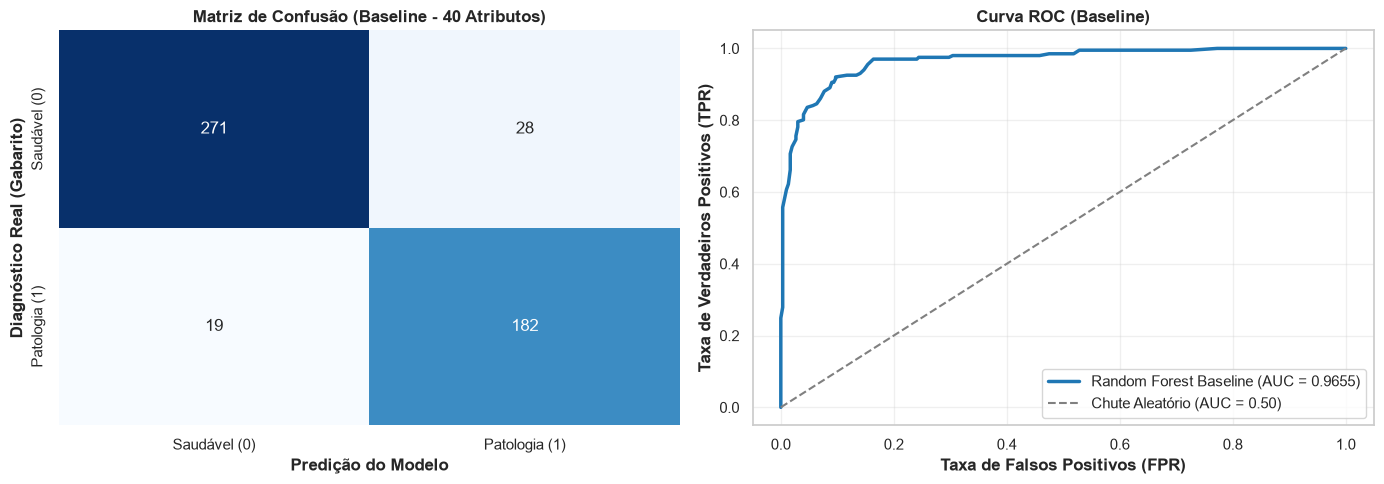

[+] Gráficos diagnósticos renderizados e salvos com sucesso em: modulo1_baseline_metrics.png


In [6]:
# 1. Definimos a funcao para plotar a matriz de confusao e a curva ROC lado a lado
def gerar_graficos_baseline(y_test, y_pred, y_proba, output_path="modulo1_baseline_metrics.png"):
    """
    Gera a Matriz de Confusão e a Curva ROC do modelo Baseline e exibe na tela.
    """
    # 2. Criamos a figura grafica contendo 1 linha e 2 colunas de subgraficos
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # 3. Calculamos a matriz de confusao numerica comparando o gabarito real contra as predicoes
    cm = confusion_matrix(y_test, y_pred)
    
    # 4. Plotamos o mapa de calor com anotacoes inteiras destacando os quadrantes clinicos
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
    axes[0].set_title("Matriz de Confusão (Baseline - 40 Atributos)", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Predição do Modelo", fontweight="bold")
    axes[0].set_ylabel("Diagnóstico Real (Gabarito)", fontweight="bold")
    axes[0].set_xticklabels(["Saudável (0)", "Patologia (1)"])
    axes[0].set_yticklabels(["Saudável (0)", "Patologia (1)"])
    
    # 5. Calculamos as taxas de falsos positivos (fpr) e verdadeiros positivos (tpr) para varios limiares
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = roc_auc_score(y_test, y_proba)
    
    # 6. Plotamos a curva ROC azul do modelo e a linha tracejada diagonal de referencia aleatoria
    axes[1].plot(fpr, tpr, color="#1f77b4", lw=2.5, label=f"Random Forest Baseline (AUC = {auc_val:.4f})")
    axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1.5, label="Chute Aleatório (AUC = 0.50)")
    axes[1].set_title("Curva ROC (Baseline)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Taxa de Falsos Positivos (FPR)", fontweight="bold")
    axes[1].set_ylabel("Taxa de Verdadeiros Positivos (TPR)", fontweight="bold")
    axes[1].legend(loc="lower right")
    axes[1].grid(True, alpha=0.3)
    
    # 7. Ajustamos o espacamento entre os eixos para evitar sobreposicao de textos
    plt.tight_layout()
    
    # 8. Salvamos a figura em arquivo de alta resolucao no disco
    plt.savefig(output_path, dpi=300)
    
    # 9. Exibimos a figura interativamente na saida do Google Colab
    plt.show()
    print(f"[+] Gráficos diagnósticos renderizados e salvos com sucesso em: {output_path}")

# 10. Chamamos a funcao para renderizar os graficos do baseline
gerar_graficos_baseline(y_test, y_pred_base, y_proba_base)

---

### Bloco 1.7 — Teste de Sanidade Automatizado do Modelo Baseline

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que é um Sanity Check (Teste de Sanidade) em Machine Learning?**  
> É uma validação programática usando asserções (`assert`) para confirmar que o modelo foi treinado com integridade matemática mínima (ex: usou exatamente 40 atributos, não desmoronou em acurácia e cronometrou um tempo válido). Se qualquer condição falhar, o código interrompe a execução com um alerta.

In [7]:
# 1. Definimos a funcao de teste de sanidade automatizada
def teste_de_sanidade(metricas, X_train):
    """
    Validação automatizada de integridade estrutural e preditiva do Módulo 1.
    """
    # 2. Verificamos se o numero de atributos no treino e rigorosamente igual a 40
    assert metricas["num_atributos"] == 40, f"Erro: Esperado 40 atributos, obtido {metricas['num_atributos']}"
    
    # 3. Verificamos se a acuracia do baseline e clinicamente viavel (superior a 70%)
    assert metricas["acuracia"] > 0.70, f"Erro: Acurácia muito baixa ({metricas['acuracia']:.2f})"
    
    # 4. Verificamos se a contagem de tempo de treinamento foi maior que zero
    assert metricas["tempo_treino_s"] > 0, "Erro: Tempo de treino inválido"
    
    # 5. Exibimos a mensagem de aprovacao se todas as checagens passarem
    print("\n[OK] SANITY CHECK PASSOU COM LOUVOR: Modelo treinado, tempo medido e métricas validadas com sucesso!")

# 6. Invocamos a funcao de teste de sanidade
teste_de_sanidade(metricas_base, X_train)


[OK] SANITY CHECK PASSOU COM LOUVOR: Modelo treinado, tempo medido e métricas validadas com sucesso!


---

## Módulo 4: Prática Orientada & Experimentação Fácil

### Roteiro de Personalização para o Estudante:
Neste exercício, você testará experimentalmente o impacto de aumentar o ruído nos laudos médicos (`flip_y`).

1. **Altere o ruído de laudo:** No código abaixo, na linha `novo_flip_y = 0.03`, mude para `0.15` (15% de erro humano no hospital) ou `0.30` (30% de ruído).
2. **Execute a célula:** Observe como a Acurácia e o F1-Score caem drasticamente, mesmo o modelo ainda tendo acesso aos 40 atributos!

In [8]:
# =============================================================================
# CÓDIGO BASE PRONTO PARA SUA EXPERIMENTAÇÃO
# =============================================================================
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# -----------------------------------------------------------------------------
# STEP 1: PASSO DE EXPERIMENTAÇÃO DO ALUNO — ALTERE O VALOR DO RUÍDO ABAIXO:
# -----------------------------------------------------------------------------
novo_flip_y = 0.15  # Tente alterar para 0.01 (cenário ideal) ou 0.30 (cenário caótico)

# 1. Geramos um novo dataset experimental aplicando o percentual de ruido configurado pelo aluno
X_exp, y_exp = make_classification(
    n_samples=1500,
    n_features=40,
    n_informative=10,
    n_redundant=10,
    flip_y=novo_flip_y,
    random_state=42
)

# 2. Particionamos em treino e teste
X_tr_exp, X_te_exp, y_tr_exp, y_te_exp = train_test_split(X_exp, y_exp, test_size=0.25, random_state=42)

# 3. Ajustamos a floresta aleatoria
clf_exp = RandomForestClassifier(n_estimators=50, random_state=42)
clf_exp.fit(X_tr_exp, y_tr_exp)

# 4. Avaliamos o impacto preditivo
preds_exp = clf_exp.predict(X_te_exp)
print(f"--- RESULTADO COM RUÍDO DE RÓTULO FLIP_Y = {novo_flip_y:.2f} ---")
print(f"📊 Acurácia Resultante: {accuracy_score(y_te_exp, preds_exp):.4f}")
print(f"📊 F1-Score Resultante: {f1_score(y_te_exp, preds_exp):.4f}")

--- RESULTADO COM RUÍDO DE RÓTULO FLIP_Y = 0.15 ---
📊 Acurácia Resultante: 0.8160
📊 F1-Score Resultante: 0.8099


---

### 🔮 Aquecimento & Spoiler da Próxima Aula (Para Ir Além)

> 🧠 **Conceito-Semente — A Ilusão da Caixa-Preta**  
> Nosso modelo Baseline atingiu um bom F1-score (~85%), mas responda com sinceridade: **ele tomou suas decisões olhando para os biomarcadores verdadeiros ou memorizou padrões aleatórios do ruído metabólico?** Olhando apenas para a matriz de confusão, é impossível responder!  
> Na **Aula 02**, utilizaremos o **SHAP (SHapley Additive exPlanations)**, uma técnica baseada no Prêmio Nobel de Economia, para calcular a contribuição exata de cada um dos 40 atributos em cada decisão da máquina!
> 
> 🚀 **Desafio Proativo de Autoestudo (Opcional):**  
> Pesquise sobre o matemático **Lloyd Shapley** e tente descobrir por que o conceito formulado por ele em 1953 para resolver conflitos de coalizões financeiras virou a maior ferramenta de explicabilidade de IA 60 anos depois!

## Módulo 5: Checklist de Autonomia do Estudante

- [ ] Compreendi a diferença prática e matemática entre atributos informativos, redundantes e ruídos.
- [ ] Entendi o conceito do Mal da Dimensionalidade e por que mais colunas nem sempre geram mais inteligência.
- [ ] Sei implementar e justificar a divisão estratificada com `stratify=y` em problemas médicos.
- [ ] Dominei o treinamento do modelo Baseline com `RandomForestClassifier` e a cronometria de latência.
- [ ] Sei interpretar uma Matriz de Confusão e calcular o F1-Score e o ROC-AUC.
- [ ] Executei o teste de sanidade automatizado e realizei o experimento com diferentes taxas de ruído.

## Referências Bibliográficas & Documentações Oficiais

- 📖 **Livro Texto:** Géron, A. — *Mãos à Obra: Aprendizado de Máquina com Scikit-Learn, Keras & TensorFlow* (Capítulo 3: Classificação e Métricas de Desempenho).
- 📄 **Artigo Histórico:** Hughes, G. F. (1968). *On the mean accuracy of statistical pattern recognizers*. IEEE Transactions on Information Theory.
- 🔗 **Documentação Oficial Scikit-Learn:** [Random Forests Classifier Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)